---
# Datos

In [37]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ruta_carpeta = os.getcwd()

df_features = pd.read_parquet(os.path.join(ruta_carpeta, 'features.parquet'))
df_lcs = pd.read_parquet(os.path.join(ruta_carpeta, 'lcs.parquet'))
df_oids = pd.read_parquet(os.path.join(ruta_carpeta, 'oids.parquet'))

print('df_features:', df_features.shape, '-> features por objeto')
print('df_lcs:     ', df_lcs.shape, '-> observaciones de las curvas de luz')
print('df_oids:    ', df_oids.shape, '-> clase de cada objeto')

df_features: (8419, 179) -> features por objeto
df_lcs:      (5189550, 31) -> observaciones de las curvas de luz
df_oids:     (9829, 2) -> clase de cada objeto


In [68]:
#EXTRACTO DE DATOS 
print('FEATURES')
display(df_features.head())

print('CURVAS DE LUZ')
display(df_lcs.head())

print('CLASES')
display(df_oids.tail())

FEATURES


,oid,Q31_r,Rcs_r,Skew_r,SmallKurtosis_r,Std_r,StetsonK_r,Pvar_r,ExcessVar_r,PairSlopeTrend_r,...,max_diffmaglim_after_fid_g,median_diffmaglim_after_fid_g,delta_mag_fid_r,delta_mjd_fid_r,first_mag_r,mean_mag_r,min_mag_r,n_det_r,PercentAmplitude_r,Harmonics_mag_5_r
0,ZTF18abmrdyx,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,20.6052,20.102501,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,ZTF18abdvyys,0.657821,0.184957,-0.453637,-1.119874,0.347335,0.912642,1.0,0.000661,0.033333,...,20.2962,19.485350,1.063133,1362.247535,13.470280,13.492689,12.974045,22.0,0.048942,0.114427
2,ZTF18abjgfrd,0.241344,0.204626,0.171970,-1.878280,0.119813,0.960020,1.0,0.000053,-0.033333,...,NaN,NaN,0.309963,1362.159144,16.484390,16.323530,16.177994,37.0,0.015189,0.236205
3,ZTF20aaksrbb,0.063570,0.436321,0.481466,-0.290408,0.042348,0.849919,1.0,0.000008,0.100000,...,21.0254,20.326300,0.117467,614.180752,14.485116,14.481151,14.436781,10.0,0.005410,260.767868
4,ZTF18abwqcoy,0.090321,0.237630,1.273315,0.891479,0.341080,0.738760,1.0,0.000303,0.066667,...,21.2738,20.220000,0.893099,797.913345,19.131857,19.246591,19.026735,13.0,0.044680,448.948945


CURVAS DE LUZ


,oid,tid,mjd,candid,fid,pid,diffmaglim,isdiffpos,nid,distnr,...,drb,magapbig,sigmagapbig,rfid,has_stamp,corrected,dubious,step_id_corr,phase,parent_candid
0,ZTF18aaasdsx,ztf,58534.325521,780325525915010000,2,780325525915,19.043385,-1,780,0.610149,...,0.000000,17.6957,0.1103,1.706120e+09,False,True,False,bulk_1.0.0,0.0,7.862174e+17
1,ZTF18aaasdsx,ztf,58540.217419,786217415915010005,2,786217415915,20.599041,-1,786,0.096748,...,0.000000,18.3134,0.0638,1.706120e+09,True,True,False,bulk_1.0.0,0.0,0.000000e+00
2,ZTF18aaasdsx,ztf,58585.142894,831142895915010001,2,831142895915,19.849493,-1,831,0.081787,...,0.000000,17.8272,0.0752,1.706120e+09,True,True,False,bulk_1.0.0,0.0,0.000000e+00
3,ZTF18aaasdsx,ztf,60539.508808,2785508805915015004,2,2785508805915,18.699131,1,2785,0.642389,...,0.998189,18.1633,0.2563,1.706120e+09,True,True,False,24.5.1,0.0,NaN
4,ZTF18aaasdsx,ztf,60539.509282,2785509285915015003,2,2785509285915,18.652796,1,2785,0.036393,...,0.999355,18.4842,0.3564,1.706120e+09,True,True,False,24.5.1,0.0,NaN


CLASES


,oid,alerceclass,tiene_features
index,,,
33864,ZTF19aaxpxxb,RRL,True
21599,ZTF18aaivxku,RRL,True
37877,ZTF18abmjvmv,RRL,True
38663,ZTF18aaaugth,RRL,False
9554,ZTF17aaajigv,RRL,True


In [40]:
# IDENTIFICADORES IOD EN CADA ARCHIVO 
print('Objetos únicos por archivo')
print('   df_features:', df_features['oid'].nunique())
print('   df_lcs:     ', df_lcs['oid'].nunique())
print('   df_oids:    ', df_oids['oid'].nunique())

print()
print('oids repetidos')
print('   df_features:', df_features['oid'].duplicated().any())
print('   df_oids:    ', df_oids['oid'].duplicated().any())

Objetos únicos por archivo
   df_features: 8419
   df_lcs:      9374
   df_oids:     9829

oids repetidos
   df_features: False
   df_oids:     False


alerceclass
EB      3000
RRL     3000
LPV     1502
CEP     1498
DSCT     829
Name: count, dtype: int64

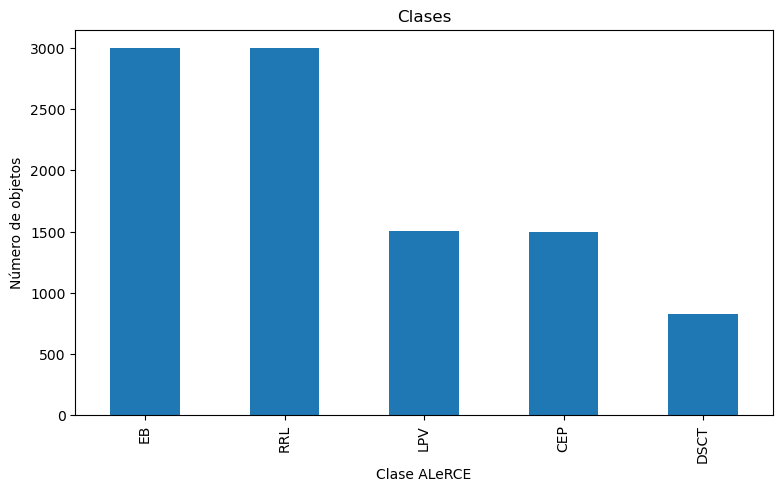

In [42]:
# Distribución de clases
conteo_clases = df_oids['alerceclass'].value_counts()
display(conteo_clases)

conteo_clases.plot(kind='bar', figsize=(9, 5))
plt.xlabel('Clase ALeRCE')
plt.ylabel('Número de objetos')
plt.title('Clases')
plt.show()

In [47]:
# OBJETOS CON FEATURES 
df_oids['tiene_features'] = df_oids['oid'].isin(df_features['oid'])

resumen = df_oids.groupby('alerceclass').agg(total=('oid', 'count'),con_features=('tiene_features', 'sum'))
resumen['sin_features'] = resumen['total'] - resumen['con_features']
display(resumen)

,total,con_features,sin_features
alerceclass,,,
CEP,1498,1172,326
DSCT,829,532,297
EB,3000,2689,311
LPV,1502,1374,128
RRL,3000,2652,348


In [ ]:
#RELACIONAR OIDS DE FEATURES CON CLASES 
X = df_features.drop(columns='oid')
oids = df_features['oid']
labels = df_features[['oid']].merge(df_oids, on='oid', how='left')['alerceclass']

print('X:', X.shape)
print('Clases:', labels.value_counts().to_dict())
print(oids)
print(labels)


X: (8419, 178)
Clases: {'EB': 2689, 'RRL': 2652, 'LPV': 1374, 'CEP': 1172, 'DSCT': 532}
0       ZTF18abmrdyx
1       ZTF18abdvyys
2       ZTF18abjgfrd
3       ZTF20aaksrbb
4       ZTF18abwqcoy
            ...     
8414    ZTF17aabdvwy
8415    ZTF19aaxpxxb
8416    ZTF18aaivxku
8417    ZTF18abmjvmv
8418    ZTF17aaajigv
Name: oid, Length: 8419, dtype: object
0       CEP
1       CEP
2       CEP
3       CEP
4       CEP
       ... 
8414    RRL
8415    RRL
8416    RRL
8417    RRL
8418    RRL
Name: alerceclass, Length: 8419, dtype: object


In [56]:
# DATOS FALTANTES EN FEATURES 

print('Total de NaN:', X.isna().sum().sum())
print('Features con al menos un NaN:', (X.isna().sum() > 0).sum(), 'de', X.shape[1])


Total de NaN: 131480
Features con al menos un NaN: 166 de 178


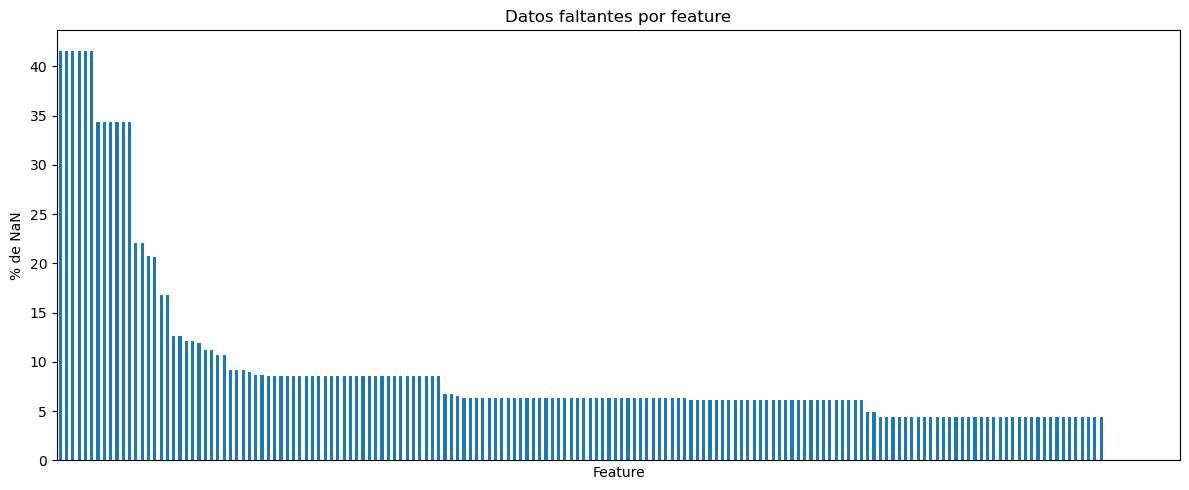

last_diffmaglim_before_fid_g      41.6
last_mjd_before_fid_g             41.6
dmag_non_det_fid_g                41.6
dmag_first_det_fid_g              41.6
max_diffmaglim_before_fid_g       41.6
median_diffmaglim_before_fid_g    41.6
dmag_first_det_fid_r              34.4
dmag_non_det_fid_r                34.4
last_mjd_before_fid_r             34.4
last_diffmaglim_before_fid_r      34.4
median_diffmaglim_before_fid_r    34.4
max_diffmaglim_before_fid_r       34.4
r-W3                              22.1
r-W2                              22.1
g-W3                              20.7
g-W2                              20.7
W2-W3                             16.8
W1-W2                             16.7
g-r_mean_corr_g_r                 12.6
g-r_max_corr_g_r                  12.6
dtype: float64

In [74]:
# PORCENTAJE DE NaN POR FEATURE 
nan_por_feature = X.isna().mean() * 100

nan_por_feature.sort_values(ascending=False).plot(kind='bar', figsize=(12, 5))
plt.ylabel('% de NaN')
plt.xlabel('Feature')
plt.title('Datos faltantes por feature')
plt.xticks([])
plt.tight_layout()
plt.show()

display(nan_por_feature.sort_values(ascending=False).head(20).round(1))

In [60]:
# RELACIÓN ENTRE FALTA DE DATOS Y CLASE 
nan_por_objeto = X.isna().sum(axis=1)

df_nan = pd.DataFrame({'clase': labels, 'n_nan': nan_por_objeto})
display(df_nan.groupby('clase')['n_nan'].describe().round(1))


,count,mean,std,min,25%,50%,75%,max
clase,,,,,,,,
CEP,1172.0,24.4,32.5,0.0,6.0,6.0,36.0,95.0
DSCT,532.0,12.9,19.9,0.0,0.0,6.0,12.0,94.0
EB,2689.0,11.2,20.3,0.0,0.0,6.0,12.0,99.0
LPV,1374.0,29.3,37.0,0.0,0.0,6.0,84.0,94.0
RRL,2652.0,9.7,16.1,0.0,0.0,6.0,12.0,99.0


### 1.4 ¿De dónde vienen los NaN?

Mi primera hipótesis fue que los objetos con NaN en features de banda g tendrían
pocas observaciones en esa banda. Lo comparo contra las curvas de luz.

In [75]:
# fid identifica la banda: 1 = g, 2 = r
conteo_bandas = (
    df_lcs.groupby(['oid', 'fid'])
    .size()
    .unstack(fill_value=0)
    .rename(columns={1: 'n_g', 2: 'n_r'})
)

cobertura = (
    df_features[['oid']]
    .merge(conteo_bandas, left_on='oid', right_index=True, how='left')
    .fillna(0)
)
n_g = cobertura['n_g'].to_numpy()

print('Observaciones por objeto:')
display(cobertura[['n_g', 'n_r']].describe().round(1))

Observaciones por objeto:


,n_g,n_r
count,8419.0,8419.0
mean,298.4,310.1
std,244.8,276.4
min,0.0,0.0
25%,111.0,97.5
50%,242.0,240.0
75%,430.0,450.0
max,1640.0,2439.0


In [76]:
# Los features con más NaN son todos de no-detecciones previas a la primera alerta
bloque_before = [
    c for c in X.columns
    if ('_before_fid_' in c) or ('dmag_non_det_' in c) or ('dmag_first_det_' in c)
]
before_g = [c for c in bloque_before if c.endswith('_g')]

# Si falta uno del bloque, faltan todos
falta_bloque = X[before_g].isna().all(axis=1)

print('Objetos con todo el bloque g faltante:', f'{falta_bloque.mean():.1%}')
print()
print('Mediana de observaciones en g')
print('   con NaN en el bloque:', np.median(n_g[falta_bloque]))
print('   sin NaN en el bloque:', np.median(n_g[~falta_bloque]))
print()
cols_g_todos = [c for c in X.columns if c.endswith('_g')]
corr = np.corrcoef(X[cols_g_todos].isna().mean(axis=1), n_g)[0, 1]
print('Correlación (% NaN en g) vs (observaciones en g):', round(corr, 3))

Objetos con todo el bloque g faltante: 4.4%

Mediana de observaciones en g
   con NaN en el bloque: 0.0
   sin NaN en el bloque: 255.0

Correlación (% NaN en g) vs (observaciones en g): -0.286


**La hipótesis era falsa.** Los objetos a los que les falta el bloque tienen *más*
observaciones en g (255) que los que lo tienen completo (232), y la correlación es
débil (−0.29).

Revisando qué son esos features: miden **no-detecciones previas a la primera alerta**.

Lo mismo pasa con los colores WISE: son un cruce con un catálogo infrarrojo externo,
y el NaN significa "sin contraparte".


In [77]:
# Separo los dos bloques problemáticos del resto
bloque_wise = [c for c in X.columns if ('W1' in c or 'W2' in c or 'W3' in c)]
features_descartados = sorted(set(bloque_before) | set(bloque_wise))

print('Bloque no-detecciones:', len(bloque_before), 'features')
print('   NaN medio:', f'{X[bloque_before].isna().mean().mean():.1%}')
print()
print('Bloque WISE:', len(bloque_wise), 'features')
print('   NaN medio:', f'{X[bloque_wise].isna().mean().mean():.1%}')
print()
resto = X.drop(columns=features_descartados)
print('Resto:', resto.shape[1], 'features')
print('   NaN máximo:', f'{resto.isna().mean().max():.1%}')

Bloque no-detecciones: 14 features
   NaN medio: 33.3%

Bloque WISE: 6 features
   NaN medio: 19.8%

Resto: 158 features
   NaN máximo: 12.6%


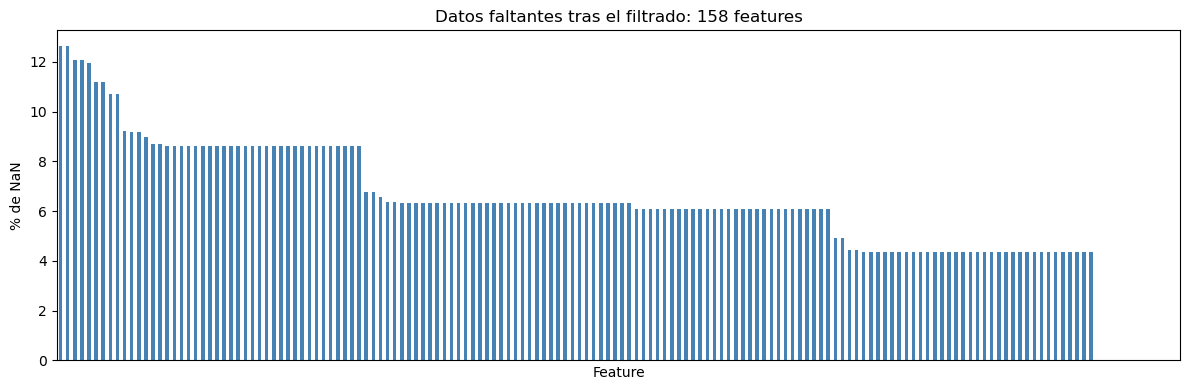

Features con más NaN tras el filtrado:


g-r_max_corr_g_r     12.6
g-r_mean_corr_g_r    12.6
MHPS_high_r          12.1
MHPS_ratio_r         12.1
MHPS_low_r           12.0
MHPS_PN_flag_r       11.2
MHPS_non_zero_r      11.2
g-r_max_g_r          10.7
g-r_mean_g_r         10.7
SPM_chi_r             9.2
MHPS_ratio_g          9.2
MHPS_high_g           9.2
MHPS_low_g            9.0
MHPS_PN_flag_g        8.7
MHPS_non_zero_g       8.7
dtype: float64

In [82]:
# PORCENTAJE DE NaN POR FEATURE DESPUÉS DEL FILTRADO
nan_despues = resto.isna().mean() * 100

nan_despues.sort_values(ascending=False).plot(kind='bar', figsize=(12, 4), color='steelblue')
plt.ylabel('% de NaN')
plt.xlabel('Feature')
plt.title(f'Datos faltantes tras el filtrado: {len(nan_despues)} features')
plt.xticks([])
plt.tight_layout()
plt.show()

# Los 15 features con más NaN de los que quedan
print('Features con más NaN tras el filtrado:')
display(nan_despues.sort_values(ascending=False).head(15).round(1))

print()


###  Estructura del missingness por banda


In [70]:
# CANTIDAD DE ELEMENTOS POR BANDA 
cols_color = [c for c in resto.columns if c.endswith('_g_r')]
cols_g_resto = [c for c in resto.columns if c.endswith('_g') and c not in cols_color]
cols_r_resto = [c for c in resto.columns if c.endswith('_r') and c not in cols_color]
cols_sin_banda = [c for c in resto.columns if c not in cols_g_resto + cols_r_resto + cols_color]

for nombre, cols in [('solo g', cols_g_resto), ('solo r', cols_r_resto), ('multibanda g-r', cols_color), ('sin banda', cols_sin_banda)]: print(f'   {nombre:15s} {len(cols):3d} features')

print()
print('Features sin banda:', cols_sin_banda)

   solo g           71 features
   solo r           71 features
   multibanda g-r   12 features
   sin banda         4 features

Features sin banda: ['gal_b', 'gal_l', 'rb', 'sgscore1']


In [ ]:

tramos = [(-.01, .01, '0% (ninguno)'), (.01, .50, '1-50%'),
          (.50, .99, '50-99%'), (.99, 1.01, '100% (todos)')]

resumen_bandas = {}

for banda, cols in [('g', cols_g_resto), ('r', cols_r_resto)]:
    frac = resto[cols].isna().mean(axis=1)
    resumen_bandas[banda] = pd.Series(
        {etq: ((frac > inf) & (frac <= sup)).sum() for inf, sup, etq in tramos}
    )

tabla = pd.DataFrame(resumen_bandas)
tabla.columns = ['banda g', 'banda r']
tabla['% g'] = (100 * tabla['banda g'] / len(resto)).round(1)
tabla['% r'] = (100 * tabla['banda r'] / len(resto)).round(1)

print('Objetos según el % de features de esa banda que están en NaN:')
display(tabla[['banda g', '% g', 'banda r', '% r']])

Objetos según el % de features de esa banda que están en NaN:


,banda g,% g,banda r,% r
0% (ninguno),7622,90.5,7379,87.6
1-50%,387,4.6,480,5.7
50-99%,42,0.5,26,0.3
100% (todos),368,4.4,534,6.3


### Escalas de los features


In [107]:
# Rango total dividido por el IQR
q25, q75 = X.quantile(.25), X.quantile(.75)
razon = ((X.max() - X.min()) / (q75 - q25).replace(0, np.nan)).dropna()

print('Features con rango/IQR > 1e4:', (razon > 1e4).sum())
display(razon.sort_values(ascending=False).head(10))

print()
for c in ['AndersonDarling_g', 'Harmonics_mag_3_r', 'MHPS_ratio_r']:
    s = X[c].dropna()
    print(f'{c}')
    print(f'   min={s.min():.4g}  mediana={s.median():.4g}  max={s.max():.4g}'
          f'  IQR={s.quantile(.75) - s.quantile(.25):.3e}')

Features con rango/IQR > 1e4: 20


Harmonics_mag_3_r    5.668238e+13
Harmonics_mag_2_r    5.533635e+13
Harmonics_mag_5_r    1.789477e+13
Harmonics_mag_6_r    1.516750e+13
AndersonDarling_g    1.329038e+13
MHPS_ratio_r         1.292798e+13
Harmonics_mag_4_r    1.170682e+13
Harmonics_mag_1_r    5.276403e+12
Harmonics_mag_7_r    3.773016e+12
Harmonics_mag_2_g    2.354869e+12
dtype: float64


AndersonDarling_g
   min=0.1412  mediana=1  max=1  IQR=6.461e-14
Harmonics_mag_3_r
   min=0  mediana=0.06845  max=1.245e+13  IQR=2.197e-01
MHPS_ratio_r
   min=-3.701e+09  mediana=3.654  max=1.229e+14  IQR=9.505e+00


---
#  Preprocesamiento


In [ ]:
#DESCARTE DE FEATURES

from sklearn.impute import SimpleImputer

X_sel = X.drop(columns=features_descartados).copy()

print(f'Descartados {len(features_descartados)} features:')
for c in features_descartados:
    print('   ', c)
print()
print(f'Quedan {X_sel.shape[1]} features | NaN máximo: {X_sel.isna().mean().max():.1%}')

Descartados 20 features:
    W1-W2
    W2-W3
    dmag_first_det_fid_g
    dmag_first_det_fid_r
    dmag_non_det_fid_g
    dmag_non_det_fid_r
    g-W2
    g-W3
    last_diffmaglim_before_fid_g
    last_diffmaglim_before_fid_r
    last_mjd_before_fid_g
    last_mjd_before_fid_r
    max_diffmaglim_before_fid_g
    max_diffmaglim_before_fid_r
    median_diffmaglim_before_fid_g
    median_diffmaglim_before_fid_r
    n_non_det_before_fid_g
    n_non_det_before_fid_r
    r-W2
    r-W3

Quedan 158 features | NaN máximo: 12.6%


### Objetos sin una banda completa



In [ ]:
cols_g = [c for c in X_sel.columns if c.endswith('_g') and not c.endswith('_g_r')]
cols_r = [c for c in X_sel.columns if c.endswith('_r') and not c.endswith('_g_r')]

sin_banda_g = X_sel[cols_g].isna().all(axis=1)
sin_banda_r = X_sel[cols_r].isna().all(axis=1)
cobertura_completa = ~(sin_banda_g | sin_banda_r)

print(f'Sin banda g:  {sin_banda_g.sum():5d}')
print(f'Sin banda r:  {sin_banda_r.sum():5d}')
print()



Sin banda g:    368
Sin banda r:    534

Composición por clase:


### Transformaciones


In [87]:
# log1p: amplitudes de armónicos y parámetros del proceso gaussiano.
#        Todos son >= 0, así que log1p es seguro.
cols_log = [
    c for c in X_sel.columns
    if c.startswith('Harmonics_mag_') or c.startswith('GP_DRW_')
    or c.startswith('MHPS_low') or c.startswith('MHPS_high')
]
cols_log = [c for c in cols_log if (X_sel[c].dropna() >= 0).all()]

# log10: los períodos. Van de horas (DSCT) a cientos de días (LPV), 4 órdenes de
#        magnitud. En escala lineal aplastarían todo lo demás.
cols_periodo = ['Period_band_g', 'Period_band_r', 'Multiband_period_g_r']

# arcsinh: MHPS_ratio tiene valores negativos, así que no admite log.
#          arcsinh se comporta como log en las colas y es lineal cerca de 0.
cols_arcsinh = ['MHPS_ratio_g', 'MHPS_ratio_r']

X_sel[cols_log] = np.log1p(X_sel[cols_log])
X_sel[cols_periodo] = np.log10(X_sel[cols_periodo])
X_sel[cols_arcsinh] = np.arcsinh(X_sel[cols_arcsinh])

print(f'log1p:   {len(cols_log)} features')
print(f'log10:   {len(cols_periodo)} features (períodos)')
print(f'arcsinh: {len(cols_arcsinh)} features')

log1p:   20 features
log10:   3 features (períodos)
arcsinh: 2 features


### Ajuste e imputación

In [ ]:
# RECORTAR VALORES EXTREMOS 
limite_inf = X_sel.quantile(.01)
limite_sup = X_sel.quantile(.99)
n_recortadas = int(((X_sel < limite_inf) | (X_sel > limite_sup)).to_numpy().sum())

X_win = X_sel.apply(lambda s: s.clip(limite_inf[s.name], limite_sup[s.name]))

print(f'Celdas recortadas: {n_recortadas} ({n_recortadas / X_sel.size:.3%} del total)')

# IMPUTAR POR MEDIANA 
X_imp = pd.DataFrame(
    SimpleImputer(strategy='median').fit_transform(X_win),
    columns=X_win.columns,
    index=X_win.index,
)

print('NaN tras imputar:', int(X_imp.isna().sum().sum()))

Celdas recortadas: 22317 (1.678% del total)
NaN tras imputar: 0


### Escalado 

(valor − mediana) / IQR 


In [103]:
mediana = X_imp.median()
iqr = X_imp.quantile(.75) - X_imp.quantile(.25)
rango_p90 = X_imp.quantile(.95) - X_imp.quantile(.05)
rango_total = X_imp.max() - X_imp.min()

escala = iqr.copy()
degenerados = []

for c in X_imp.columns:
    referencia = max(abs(mediana[c]), rango_total[c], 1e-12)
    if iqr[c] <= 1e-6 * referencia:
        alternativa = rango_p90[c] if rango_p90[c] > 1e-6 * referencia else rango_total[c]
        escala[c] = alternativa if alternativa > 0 else 1.0
        degenerados.append(c)

X_esc = (X_imp - mediana) / escala



---
# 3. UMAP



In [ ]:
import umap

reductor = umap.UMAP(
    n_neighbors=15,     
    min_dist=0.1,      
    n_components=2,
    metric='euclidean',
    random_state=42,
)

embedding = reductor.fit_transform(X_esc)

df_umap = pd.DataFrame(embedding, columns=['UMAP1', 'UMAP2'])
df_umap['oid'] = oids.to_numpy()
df_umap['clase'] = labels.to_numpy()
df_umap['cobertura_completa'] = cobertura_completa.to_numpy()

print('Embedding:', embedding.shape)
display(df_umap.head())

c:\Users\fonse\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Embedding: (8419, 2)


,UMAP1,UMAP2,oid,clase,cobertura_completa
0,13.331541,5.171874,ZTF18abmrdyx,CEP,False
1,11.533051,-3.071598,ZTF18abdvyys,CEP,True
2,14.041310,6.095970,ZTF18abjgfrd,CEP,False
3,2.518110,6.115031,ZTF20aaksrbb,CEP,True
4,2.226954,4.017185,ZTF18abwqcoy,CEP,True


### Proyección por clase

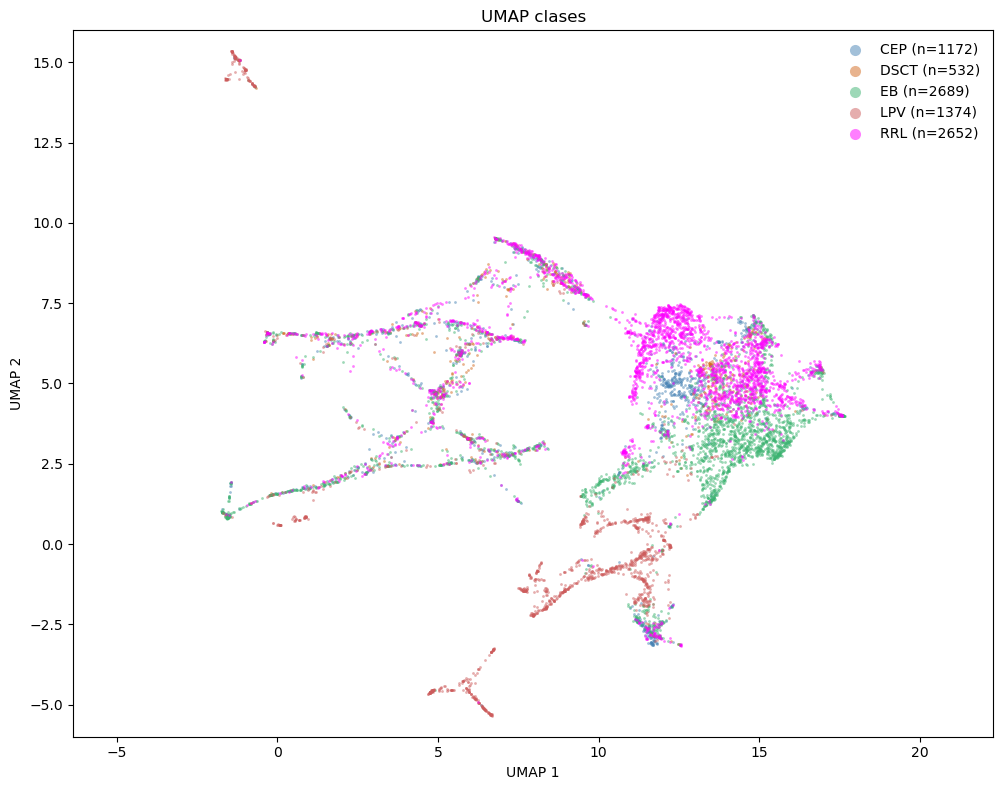

In [102]:
colores = {
    'CEP':  'steelblue',
    'DSCT': 'chocolate',
    'EB':   'mediumseagreen',
    'LPV':  'indianred',
    'RRL':  'magenta',
}

fig, ax = plt.subplots(figsize=(10, 8))

for clase, color in colores.items():
    sub = df_umap[df_umap['clase'] == clase]
    ax.scatter(sub['UMAP1'], sub['UMAP2'], s=4, alpha=.5,
               c=color, label=f'{clase} (n={len(sub)})', linewidths=0)

ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
ax.set_title(f'UMAP clases')
ax.legend(markerscale=4, frameon=False)
ax.set_aspect('equal', adjustable='datalim')
plt.tight_layout()
plt.show()

###  Objetos sin cobertura completa

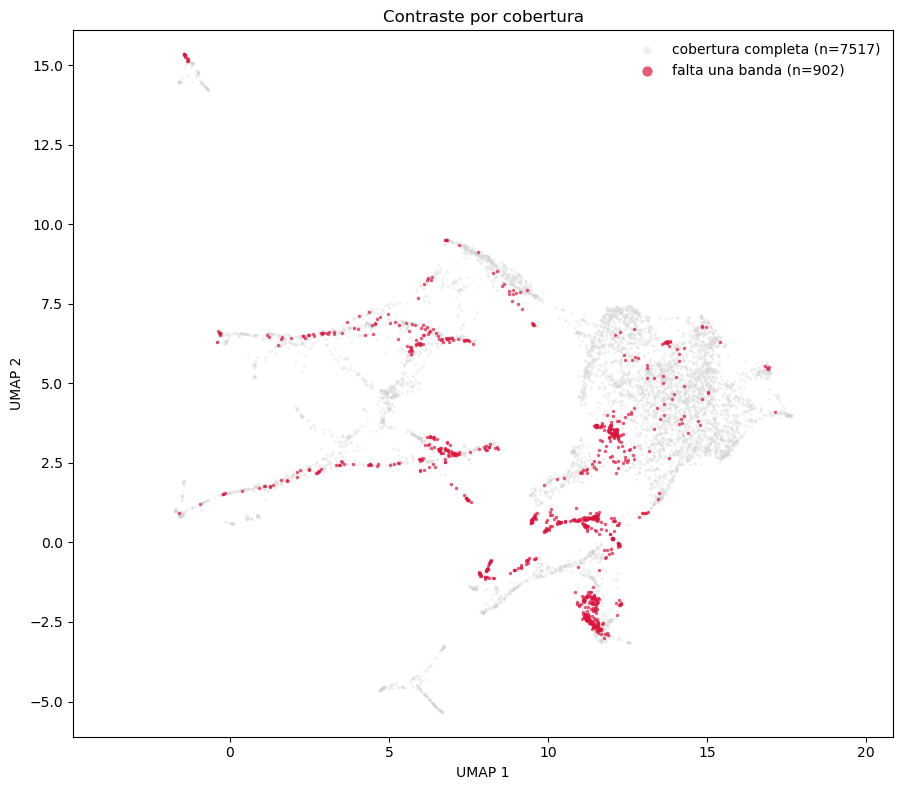

In [99]:
# CONTRASTE POR COBERTURA
completos = df_umap[df_umap['cobertura_completa']]
incompletos = df_umap[~df_umap['cobertura_completa']]

fig, ax = plt.subplots(figsize=(9, 8))

ax.scatter(completos['UMAP1'], completos['UMAP2'], s=4, alpha=.3,
           c='lightgray', linewidths=0, label=f'cobertura completa (n={len(completos)})')
ax.scatter(incompletos['UMAP1'], incompletos['UMAP2'], s=6, alpha=.7,
           c='crimson', linewidths=0, label=f'falta una banda (n={len(incompletos)})')

ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
ax.set_title('Contraste por cobertura')
ax.legend(markerscale=3, frameon=False)
ax.set_aspect('equal', adjustable='datalim')

plt.tight_layout()
plt.show()

### n_neighbors



c:\Users\fonse\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\fonse\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\fonse\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
c:\Users\fonse\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


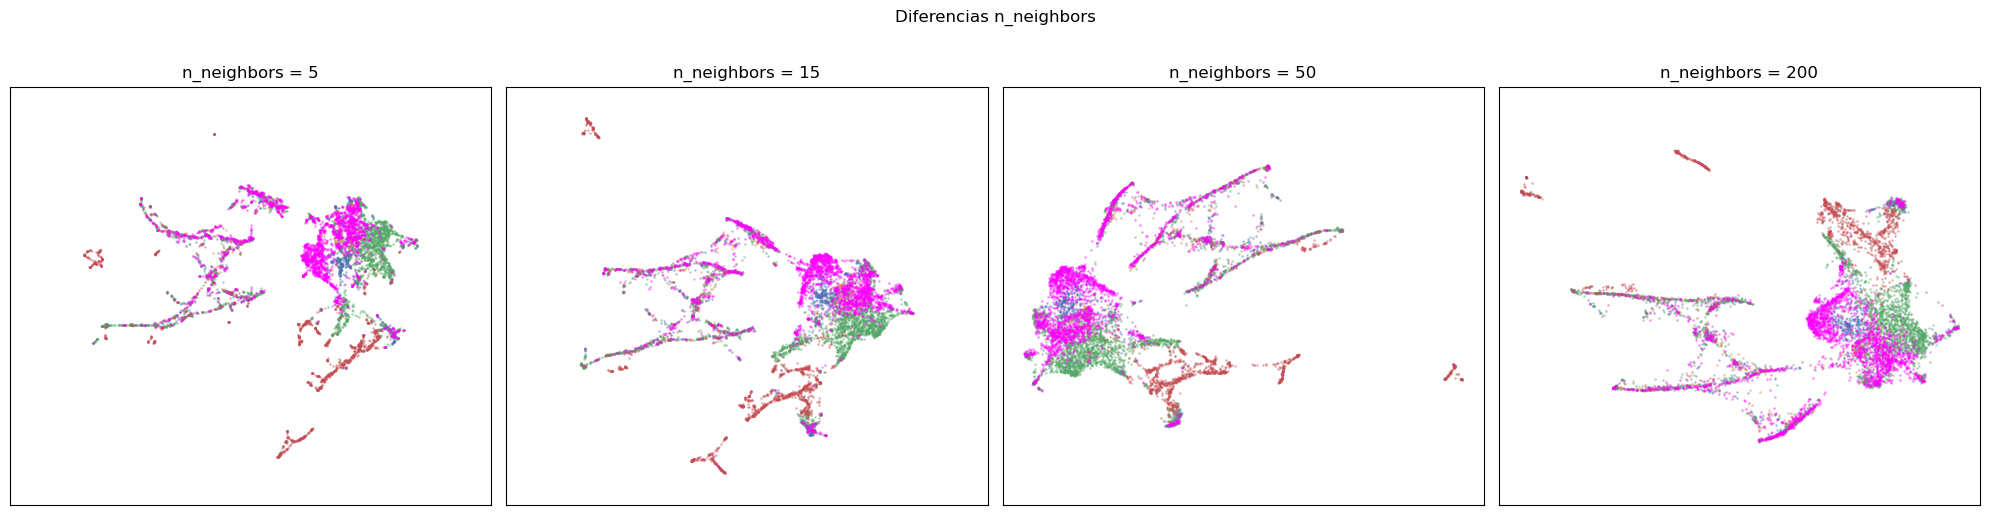

In [100]:
valores_n = [5, 15, 50, 200]
clases = labels.to_numpy()

fig, axes = plt.subplots(1, len(valores_n), figsize=(5 * len(valores_n), 5))

for ax, n in zip(axes, valores_n):
    emb = umap.UMAP(n_neighbors=n, min_dist=0.1, n_components=2,
                    random_state=42).fit_transform(X_esc)

    for clase, color in colores.items():
        m = (clases == clase)
        ax.scatter(emb[m, 0], emb[m, 1], s=3, alpha=.5, c=color, linewidths=0)

    ax.set_title(f'n_neighbors = {n}')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_aspect('equal', adjustable='datalim')

fig.suptitle('Diferencias n_neighbors', y=1.02)
plt.tight_layout()
plt.show()

---
## UMAP sin preprocesamiento



In [112]:
# UMAP SIN PREPROCESAMIENTO
X_crudo = X.fillna(X.median())

desv_crudo = X_crudo.std()
print('Escalas sin procesar:')
print(f'   std min={desv_crudo.min():.3g}  mediana={desv_crudo.median():.3g}  max={desv_crudo.max():.3g}')
print(f'   feature dominante: {desv_crudo.idxmax()}')
print()

embedding_crudo = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    random_state=42,
).fit_transform(X_crudo)


Escalas sin procesar:
   std min=0.00116  mediana=1.81  max=1.61e+12
   feature dominante: MHPS_ratio_r



c:\Users\fonse\anaconda3\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


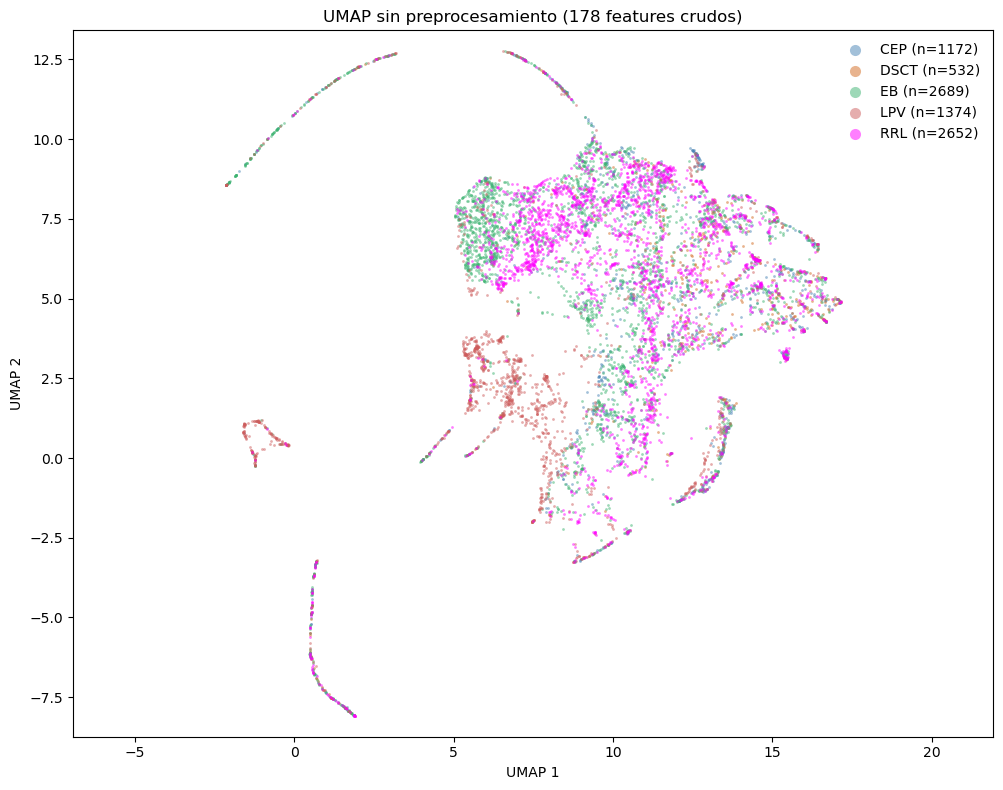

In [113]:
# PROYECCIÓN POR CLASE SIN PREPROCESAMIENTO
clases_arr = labels.to_numpy()

fig, ax = plt.subplots(figsize=(10, 8))

for clase, color in colores.items():
    m = (clases_arr == clase)
    ax.scatter(embedding_crudo[m, 0], embedding_crudo[m, 1], s=4, alpha=.5,
               c=color, label=f'{clase} (n={m.sum()})', linewidths=0)

ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
ax.set_title('UMAP sin preprocesamiento (178 features crudos)')
ax.legend(markerscale=4, frameon=False)
ax.set_aspect('equal', adjustable='datalim')
plt.tight_layout()
plt.show()